# Mouse cell atlas (two batches: Seq-Well and 10x)

Loads `/gpfs01/berens/user/sdamrich/data/ne_aligned/mouse_atlas`: 15006 genes x 6954 cells
in **one** count matrix covering both batches, plus **one** metadata table.

| file | contents |
| --- | --- |
| `filtered_total_batch1_seqwell_batch2_10x.txt.gz` | tab-separated raw counts, genes as rows, cells as columns |
| `filtered_total_sample_ext_organ_celltype_batch.txt.gz` | one row per cell, cell ids as row names |

Unlike [load_hematopoietic.ipynb](load_hematopoietic.ipynb) the batches are not in separate
files, so the split into `X1` / `X2` comes from the metadata's batch column:
`Batch1` = Seq-Well (4239 cells), `Batch2` = 10x (2715 cells). All 11 cell types occur in
both batches, so there is only one variant (`.../mouse_atlas`) and no "shared cell types"
version.

The preprocessing itself lives in
[preprocessing.py](../src/ne_aligned_utils/preprocessing.py) and the inspection plots in
[plot.py](../src/ne_aligned_utils/plot.py), shared with the other `load_*` notebooks:
Seurat-style filtering, `seurat_v3` HVG selection of 1000 genes, library-size
normalisation + `log1p`, saved as `X1.npy` / `X2.npy` / `X1_counts.npy` /
`X2_counts.npy` / `labels*.npy` / ... so the `compute_aligned_*` scripts can pick the
dataset up from a plain `dataset` string.

In [1]:
%load_ext autoreload
%autoreload 2

import os

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ne_aligned_utils.plot import plot_variant
from ne_aligned_utils.preprocessing import check_saved, describe_batches, prepare

In [2]:
base_path = "/gpfs01/berens/user/sdamrich/data/ne_aligned"

dataset = "mouse_atlas"
data_path = os.path.join(base_path, dataset)  # raw .txt.gz files live here
res_path = data_path                          # ... and the derived arrays go back into it
fig_path = os.path.join(base_path, "figures")

expr_file = os.path.join(data_path, "filtered_total_batch1_seqwell_batch2_10x.txt.gz")
meta_file = os.path.join(data_path, "filtered_total_sample_ext_organ_celltype_batch.txt.gz")

os.makedirs(fig_path, exist_ok=True)

sorted(os.listdir(data_path))

['X1.npy',
 'X1_counts.npy',
 'X2.npy',
 'X2_counts.npy',
 'cell_type_names.npy',
 'cells_metadata.csv',
 'combined_1000genes.h5ad',
 'dataset_names.npy',
 'features.txt',
 'filtered_total_batch1_seqwell_batch2_10x.txt.gz',
 'filtered_total_sample_ext_organ_celltype_batch.txt.gz',
 'labels1.npy',
 'labels2.npy']

## Raw loading

The metadata table is read first, since it decides the batch split and the labels. Its row
names are the cell ids and they match the columns of the count matrix.

The annotation comes at two granularities each, and the coarser one is used in both cases:

| column | values | used for |
| --- | --- | --- |
| `ct` | 11 harmonised cell types | the labels in `labels1.npy` / `labels2.npy` |
| `ct.orig` | 21 finer, batch-specific cell type names | nothing, only kept in `cells_metadata.csv` |
| `organ` | 8 organ systems | colouring the embeddings |
| `tissue` | 34 finer tissues | nothing, only kept in `cells_metadata.csv` |

In [3]:
meta = pd.read_csv(meta_file, sep="\t", index_col=0)  # row names are the cell ids

BATCH_COL = "batchlb"      # Batch1 = Seq-Well (MCA), Batch2 = 10x (Tabula Muris)
CELL_TYPE_COL = "ct"       # 11 types; the finer `ct.orig` (21) is not used
ORGAN_COL = "organ"        # 8 organ systems; the finer `tissue` (34) is not used

print("metadata:", meta.shape)
print("columns:", list(meta.columns))
for c in [BATCH_COL, CELL_TYPE_COL, "ct.orig", ORGAN_COL, "tissue"]:
    print(f"  {c}: {meta[c].nunique()} unique -> {sorted(meta[c].astype(str).unique())[:11]}")

meta.head()

metadata: (6954, 10)
columns: ['nGene', 'nUMI', 'orig.ident', 'batch', 'ct', 'ct.orig', 'tissue', 'organ', 'percent.mito', 'batchlb']
  batchlb: 2 unique -> ['Batch1', 'Batch2']
  ct: 11 unique -> ['B-cell', 'Dendritic', 'Endothelial', 'Epithelial', 'Macrophage', 'Monocyte', 'NK', 'Neutrophil', 'Smooth-muscle', 'Stromal', 'T-cell']
  ct.orig: 21 unique -> ['B_cell', 'Dendritic_cell', 'Endothelial_Cell', 'Endothelial_cell', 'Epithelial_cell', 'Macrophage', 'Monocyte', 'NK_cell', 'Neutrophil', 'Smooth_muscle_cell', 'Stromal_cell']
  organ: 8 unique -> ['Circulatory', 'Digestive', 'Endocrine', 'Immune', 'Lymphatic', 'Muscular', 'Nervous', 'Respiratory']
  tissue: 34 unique -> ['Aorta', 'Bladder', 'BoneMarrow', 'BoneMarrowcKit', 'Brain', 'Brain_Microglia', 'Brain_Neurons', 'Diaphragm', 'FetalBrain', 'FetalIntestine', 'FetalKidney']


,nGene,nUMI,orig.ident,batch,ct,ct.orig,tissue,organ,percent.mito,batchlb
T-cell_Thymus_1.GCGTCCGGTACACCGCTA,525,672,T-cell,1,T-cell,T_cell,Thymus,Immune,0,Batch1
T-cell_Thymus_2.CGAGTATAGTCGGTCGGT,885,1859,T-cell,1,T-cell,T_cell,Thymus,Immune,0,Batch1
T-cell_Thymus_1.TGAAGCTCAAAGCGCTTG,2199,5379,T-cell,1,T-cell,T_cell,Thymus,Immune,0,Batch1
T-cell_Thymus_1.TTAACTTATTGTGTATAC,1503,3046,T-cell,1,T-cell,T_cell,Thymus,Immune,0,Batch1
T-cell_Thymus_1.GACACTATTCCACAAAGT,1064,1535,T-cell,1,T-cell,T_cell,Thymus,Immune,0,Batch1


In [4]:
# no `dtype=` here: with `index_col=0` a scalar dtype is applied to the gene-name column as
# well and the parse fails. The float32 cast happens in `to_numpy` below, so the table is
# float64 (~840 MB) in between. If that ever gets tight, wrap the array in
# scipy.sparse.csr_matrix -- scanpy and `dense()` both take sparse input.
expr = pd.read_csv(expr_file, sep="\t", index_col=0)  # genes x cells

print("count table:", expr.shape, f"({expr.memory_usage(deep=True).sum() / 1e6:.0f} MB)")
print("genes:", list(expr.index[:3]))
print("cells:", list(expr.columns[:3]))
assert expr.shape[1] > 1, "the count table parsed as a single column -- is it tab separated?"

count table: (15006, 6954) (836 MB)
genes: ['0610005C13Rik', '0610007N19Rik', '0610007P14Rik']
cells: ['T-cell_Thymus_1.GCGTCCGGTACACCGCTA', 'T-cell_Thymus_2.CGAGTATAGTCGGTCGGT', 'T-cell_Thymus_1.TGAAGCTCAAAGCGCTTG']


In [5]:
cells = expr.columns.astype(str)
assert cells.is_unique, "duplicated cell ids in the count matrix"

# align the metadata to the columns of the count matrix instead of trusting the row order
obs = meta.set_index(meta.index.astype(str).rename("cell_id")).reindex(cells)
assert not obs.isna().all(axis=1).any(), "cells of the count matrix without metadata"
print("metadata was already in matrix order:", list(meta.index.astype(str)) == list(cells))

adata = ad.AnnData(
    X=expr.to_numpy(dtype=np.float32).T,  # genes x cells -> cells x genes
    obs=obs,
    var=pd.DataFrame(index=expr.index.astype(str).rename("gene")),
)
adata.layers["counts"] = adata.X.copy()

adata.obs["cell_type"] = pd.Categorical(adata.obs[CELL_TYPE_COL].astype(str))
adata.obs["batch"] = pd.Categorical(adata.obs[BATCH_COL].astype(str))

# Batch1 = Seq-Well and Batch2 = 10x, according to the name of the count matrix file
batch_order = ["Batch1", "Batch2"]
batch_names = ("seqwell", "10x")
assert list(adata.obs["batch"].cat.categories) == batch_order, adata.obs["batch"].cat.categories
adata.obs["method"] = pd.Categorical(
    adata.obs["batch"].astype(str).map(dict(zip(batch_order, ["data1", "data2"]))),
    categories=["data1", "data2"],
)
print("batch -> method:", dict(zip(batch_order, batch_names)))

# `expr` is kept on purpose: deleting it would make this cell impossible to re-run.
# Run `del expr` by hand if memory gets tight.
adata

metadata was already in matrix order: True


batch -> method: {'Batch1': 'seqwell', 'Batch2': '10x'}


AnnData object with n_obs × n_vars = 6954 × 15006
    obs: 'nGene', 'nUMI', 'orig.ident', 'batch', 'ct', 'ct.orig', 'tissue', 'organ', 'percent.mito', 'batchlb', 'cell_type', 'method'
    layers: 'counts'

## Minimal inspection of the raw batches

In [6]:
raw_is_integer = describe_batches(adata, batch_col="batch")

# `prepare` needs raw counts: it selects HVGs with `seurat_v3` and saves X*_counts.npy.
# It asserts this itself, so a False here means `prepare` below will refuse the matrix.
print("raw counts everywhere:", raw_is_integer)

--- Batch1 (4239 cells x 15006 genes) ---
integer counts: True | min: 0.0
zero fraction: 0.954
genes/cell   min 312, median 601, max 3252
counts/cell  min 457, median 951, max 11108

--- Batch2 (2715 cells x 15006 genes) ---
integer counts: True | min: 0.0
zero fraction: 0.847
genes/cell   min 496, median 2045, max 7226
counts/cell  min 2374, median 421790, max 1797049

raw counts everywhere: True


In [7]:
ct_by_batch = pd.crosstab(adata.obs["cell_type"], adata.obs["batch"])
print(f"{ct_by_batch.shape[0]} cell types x {ct_by_batch.shape[1]} batches")
print(ct_by_batch.to_string())
print("\nevery cell type present in both batches:", bool((ct_by_batch > 0).all().all()))

11 cell types x 2 batches
batch          Batch1  Batch2
cell_type                    
B-cell            325     781
Dendritic         202      18
Endothelial       432     702
Epithelial        355      35
Macrophage        425      44
Monocyte          386      94
NK                 36      49
Neutrophil        311     143
Smooth-muscle      97      66
Stromal           701     331
T-cell            969     452

every cell type present in both batches: True


In [8]:
print(pd.crosstab(adata.obs[ORGAN_COL].astype(str), adata.obs["batch"]).to_string())

# the finer annotations are too fine to colour a scatter plot by, but they do end up in
# cells_metadata.csv next to the arrays
print("\nfiner columns:", {c: adata.obs[c].nunique() for c in ["ct.orig", "tissue"]})

batch        Batch1  Batch2
organ                      
Circulatory     166     365
Digestive       961      22
Endocrine      1090     124
Immune          920    1024
Lymphatic       537     405
Muscular        339      62
Nervous          37     167
Respiratory     189     546

finer columns: {'ct.orig': 21, 'tissue': 34}


## Preprocessing + saving

`prepare` mirrors the Seurat pipeline of [real_data060925.R](../real_data060925.R):
`CreateSeuratObject(min.cells=3, min.features=10)`, `SelectIntegrationFeatures(nfeatures=1000)`
(via `seurat_v3` HVG on the raw counts) and `NormalizeData(LogNormalize, scale.factor=1e4)`.

A few things worth being explicit about:

- **The 1000 genes are shared by both batches**, not selected per batch. `batch_key="method"`
  makes the selection batch-*aware*: scanpy ranks genes within each batch, then picks the
  top 1000 by median rank across batches into a single `var["highly_variable"]` mask. Both
  batches are then re-indexed to the same `features` list, so `X1` and `X2` have identical
  columns in identical order.
- **Raw counts are saved too**, restricted to the selected genes and cells and in the same
  column order as `X1`/`X2` (`X1_counts.npy` / `X2_counts.npy`).
- **A 50D PCA is saved too** (`X1_pca50.npy` / `X2_pca50.npy`), fitted on `X1` stacked on
  `X2` and then split by batch. That is one PCA over both batches rather than one per batch,
  so the two blocks share a coordinate system.
- Labels are encoded over the *combined* cells, so a given integer means the same cell type
  in both batches.
- `keep_types` is left at its default (all cell types), which is what makes this dataset a
  single variant. It exists in case a subset is wanted later: cells are subset *before*
  `filter_genes` and before the HVG call, so a subset gets its own gene selection.
- Everything else in the metadata (`organ`, `tissue`, `ct.orig`, ...) is not encoded into
  `.npy` files but is written out with `cells_metadata.csv`, in the same row order as `X1`
  stacked on `X2`.

In [13]:
out = prepare(
    adata,
    res_path,
    dataset,
    batch_names=batch_names,
    extra_label_cols=[ORGAN_COL],
)

[mouse_atlas] filters dropped 0 cells and 0 genes
[mouse_atlas] joint PCA (4239, 50) + (2715, 50) -> X1_pca50.npy, X2_pca50.npy
[mouse_atlas] saved to /gpfs01/berens/user/sdamrich/data/ne_aligned/mouse_atlas


## Inspection of the saved arrays

In [10]:
check_saved(out, counts_are_integer=raw_is_integer)

--- mouse_atlas ---
X1: (4239, 1000)   X2: (2715, 1000)
11 cell types: ['B-cell', 'Dendritic', 'Endothelial', 'Epithelial', 'Macrophage', 'Monocyte', 'NK', 'Neutrophil', 'Smooth-muscle', 'Stromal', 'T-cell']
               seqwell  10x
B-cell             325  781
Dendritic          202   18
Endothelial        432  702
Epithelial         355   35
Macrophage         425   44
Monocyte           386   94
NK                  36   49
Neutrophil         311  143
Smooth-muscle       97   66
Stromal            701  331
T-cell             969  452
log-normalised range: 0.000 .. 8.004
counts files: shapes match, same sparsity pattern as X1/X2, integer: True
raw count range: 0 .. 274689
joint PCA: (6954, 50) (rows are X1 stacked on X2)


## PCA and t-SNE

Same three-panel layout as the other `load_*` notebooks: each batch on its own plus the
naive joint embedding, coloured by batch, by cell type and by organ system. Before
alignment the joint embedding is expected to split by batch.

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Finding 90 nearest neighbors using Annoy approximate search using euclidean distance...
   --> Time elapsed: 1.35 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 0.12 seconds
===> Calculating PCA-based initialization...
   --> Time elapsed: 0.00 seconds
===> Running optimization with exaggeration=12.00, lr=353.25 for 250 iterations...
Iteration   50, KL divergence 3.0506, 50 iterations in 5.5762 sec
Iteration  100, KL divergence 2.8725, 50 iterations in 4.9245 sec
Iteration  150, KL divergence 2.8145, 50 iterations in 4.8368 sec
Iteration  200, KL divergence 2.7854, 50 iterations in 4.8151 sec
Iteration  250, KL divergence 2.7692, 50 iterations in 4.8882 sec
   --> Time elapsed: 25.04 seconds
===> Running optimization with exaggeration=1.00, lr=423

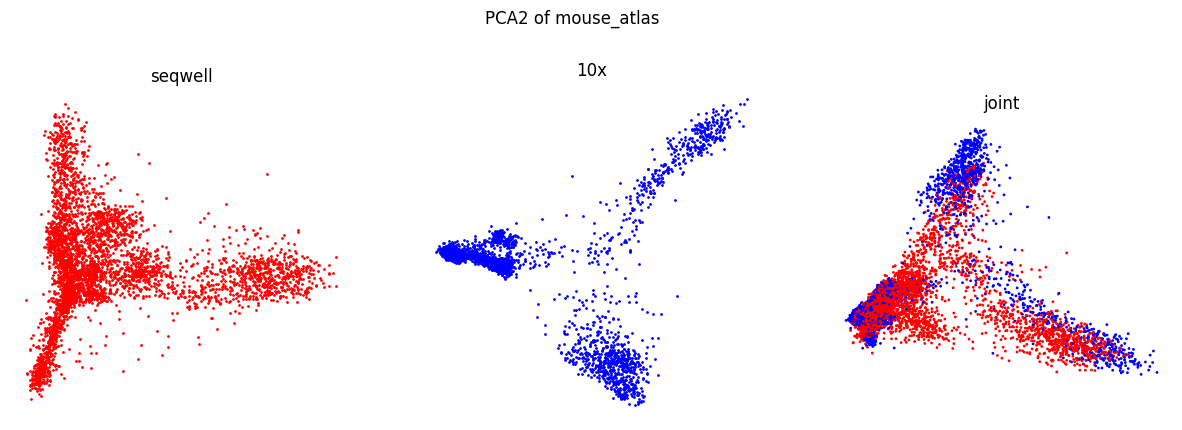

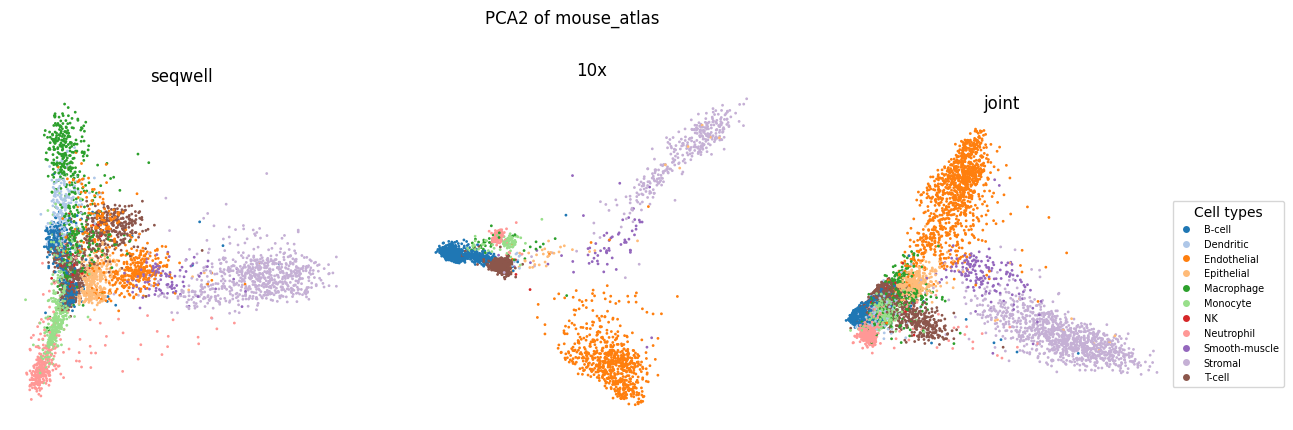

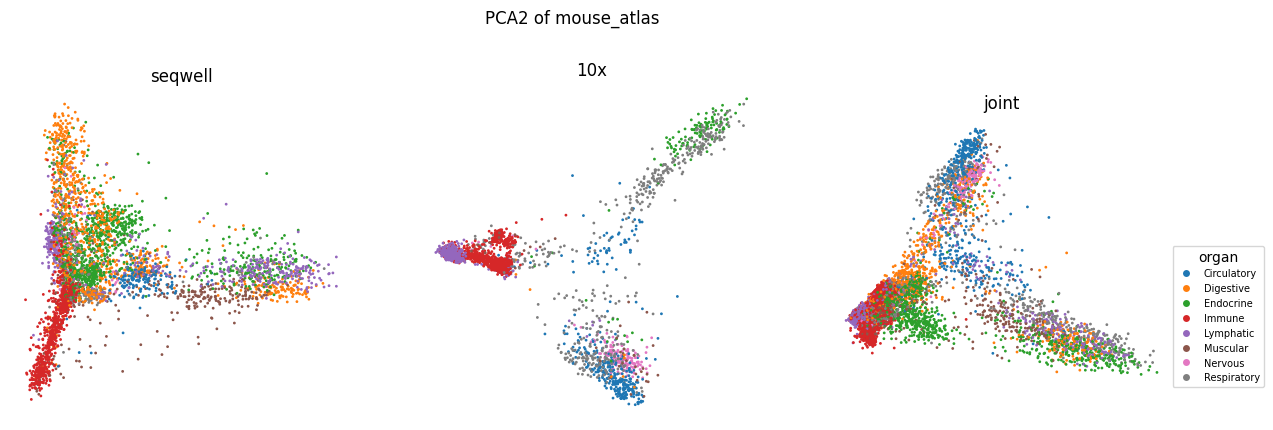

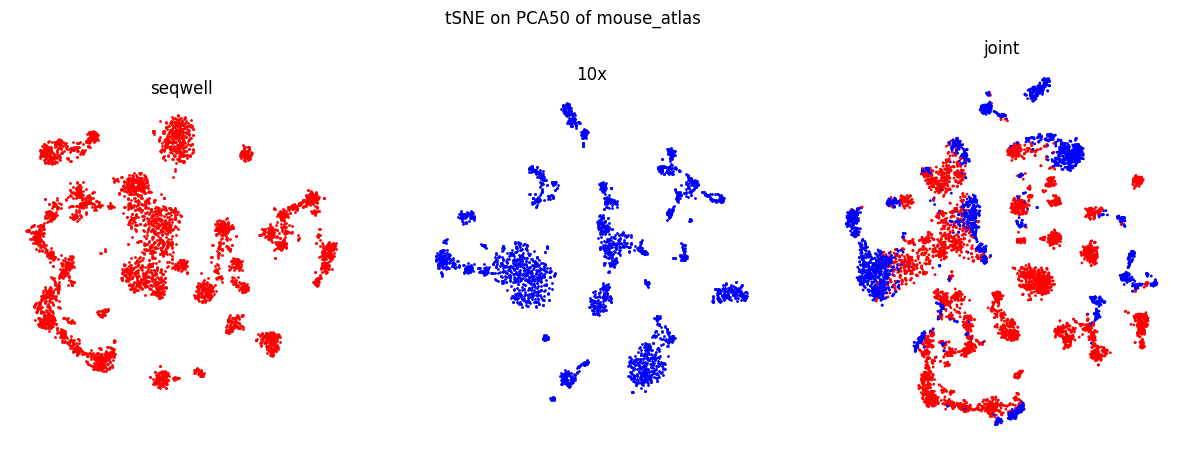

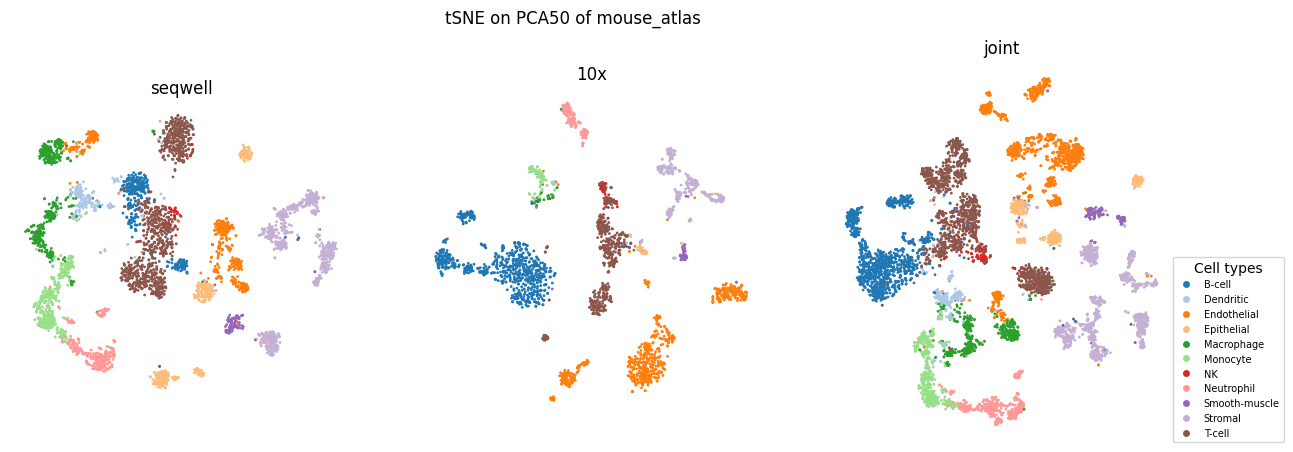

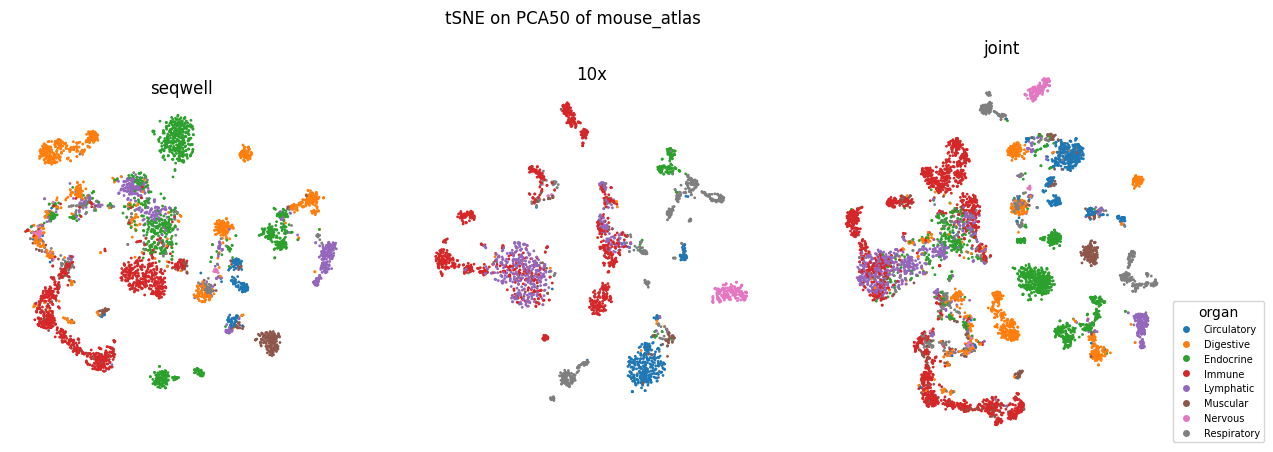

In [11]:
plot_variant(out, fig_dir=fig_path);

## Round trip

Check that the saved arrays read back the way the `compute_aligned_*` scripts expect
(`X1.npy` / `X2.npy` / `labels1.npy` / `labels2.npy` in `res_path`).

In [14]:
print(sorted(f for f in os.listdir(res_path) if not f.endswith(".txt.gz")))

X1 = np.load(os.path.join(res_path, "X1.npy"))
X2 = np.load(os.path.join(res_path, "X2.npy"))
C1 = np.load(os.path.join(res_path, "X1_counts.npy"))
C2 = np.load(os.path.join(res_path, "X2_counts.npy"))
y1 = np.load(os.path.join(res_path, "labels1.npy"))
y2 = np.load(os.path.join(res_path, "labels2.npy"))
names = np.load(os.path.join(res_path, "cell_type_names.npy"), allow_pickle=True)
batches = np.load(os.path.join(res_path, "dataset_names.npy"), allow_pickle=True)
features = pd.read_csv(os.path.join(res_path, "features.txt"))["gene"].to_list()
P1 = np.load(os.path.join(res_path, "X1_pca50.npy"))
P2 = np.load(os.path.join(res_path, "X2_pca50.npy"))
assert (P1.shape[0], P2.shape[0]) == (X1.shape[0], X2.shape[0]), "PCA misses cells"

print("X:", X1.shape, X2.shape, " counts:", C1.shape, C2.shape)
print("labels:", y1.shape, y2.shape, " features:", len(features))
print("batches:", list(batches), " types:", list(names))
print("PCA:", P1.shape, P2.shape)

['X1.npy', 'X1_counts.npy', 'X1_pca50.npy', 'X2.npy', 'X2_counts.npy', 'X2_pca50.npy', 'cell_type_names.npy', 'cells_metadata.csv', 'combined_1000genes.h5ad', 'dataset_names.npy', 'features.txt', 'labels1.npy', 'labels2.npy', 'pca50_joint.npy']
X: (4239, 1000) (2715, 1000)  counts: (4239, 1000) (2715, 1000)
labels: (4239,) (2715,)  features: 1000
batches: [np.str_('seqwell'), np.str_('10x')]  types: ['B-cell', 'Dendritic', 'Endothelial', 'Epithelial', 'Macrophage', 'Monocyte', 'NK', 'Neutrophil', 'Smooth-muscle', 'Stromal', 'T-cell']
PCA: (4239, 50) (2715, 50)
